# SEC-MALS: Mw vs cycles



In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FixedFormatter

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['CMU Serif', 'Libertinus Serif', 'DejaVu Serif'],
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'savefig.dpi': 200,
    'savefig.bbox': 'tight',
    'text.usetex' : False,
    'mathtext.fontset': 'cm'
})

# Load data
data = pd.read_csv('all_secmals.csv')

# Parse into tidy structure
samples = ['CX', 'WT', 'dL', 'dFG', 'dFGL', 'dK', 'dI']
colors = ["#999999", "#E69F00", "#56B4E9", "#009E73",
          "#F0E442", "#0072B2", "#9467BD"]
markers = {'CX': 'o', 'WT': 's', 'dL': '^', 'dFG': 'D',
           'dFGL': 'v', 'dK': 'P', 'dI': 'X'}

frames, present = [], []
for v in samples:
    sub = (data[['cycles', f'{v}_Mw', f'{v}_Mw_std', f'{v}_Rg', f'{v}_Rg_std']]
           .rename(columns={f'{v}_Mw': 'Mw',
                            f'{v}_Mw_std': 'Mw_std',
                            f'{v}_Rg': 'Rg',
                            f'{v}_Rg_std': 'Rg_std'}))
    sub = sub[sub['Mw'].notna() & sub['Rg'].notna()].copy()
    sub['sample'] = v
    frames.append(sub)
    if len(sub) > 0:
        present.append(v)
tidy = pd.concat(frames, ignore_index=True)
print('samples with data:', present)


samples with data: ['CX', 'WT', 'dL', 'dFG', 'dFGL', 'dK', 'dI']


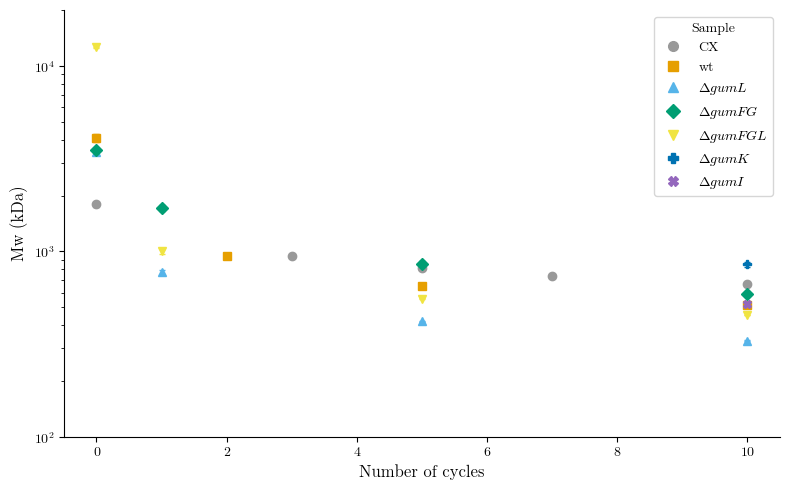

In [42]:
fig, ax = plt.subplots(figsize=(8, 5))

fit_info = []

for v in present:
    g = tidy[tidy['sample'] == v].sort_values('Mw')
    c, m = colors[samples.index(v)], markers[v]
    ax.errorbar(g['cycles'], g['Mw'],
                yerr=g['Mw_std'],
                marker=m, color=c, lw=0, ms=6,
                elinewidth=0.9, capsize=2, zorder=3)

ax.set_yscale('log')
ax.set_ylim(100, 20000)

ax.set_ylabel('Mw (kDa)', fontsize=12)
ax.set_xlabel('Number of cycles', fontsize=12)

from matplotlib.lines import Line2D as _L2
handles = []
for v in present:
    if v.startswith('d'):
        label = (r'$\mathrm{\Delta}\mathit{gum' + v[1:] + '}$')
    elif v == 'WT':
        label = 'wt'
    else:
        label = v
    handles.append(_L2([0], [0], marker=markers[v], linestyle='none', color=colors[samples.index(v)], label=label, markersize=7))

ax.legend(handles=handles, title='Sample', frameon=True, loc='upper right')

plt.tight_layout()
plt.savefig('secmals_alt5.png', dpi=300)
plt.show()
